# TQP × Temporal Event Graph — AV2 실데이터 Colab 파일럿 (Drive → Hugging Face → 공식 S3)

**실행 순서:** 상단 메뉴에서 **런타임 → 모두 실행**을 선택합니다. `Google Drive` 인증 창이 나오면 로그인하세요. GPU는 필요하지 않습니다.

1. Drive의 어떤 하위 폴더든 **같은 로그 폴더에** `annotations.feather`와 `city_SE3_egovehicle.feather`가 있으면 자동 발견합니다.
2. Drive에 부족한 로그가 있으면 Hugging Face에서 **AV2 Sensor 형식의 두 파일을 가진 저장소**를 검색하여 내려받습니다. 호환되는 미러가 없다면 다음 단계로 넘어갑니다.
3. 마지막으로 Argoverse 공식 공개 S3에서 **해당 로그의 두 Feather 파일만** 받아 Drive 캐시에 저장합니다. **1TB 센서 원본 전체를 내려받지 않습니다.**
4. 실제 객체 궤적에서 4종 행동을 검출하고 TQP를 기존 Interval 방식과 Temporal Event Graph 방식으로 실행하여 동등성과 처리시간을 비교합니다.

**중요:** Hugging Face의 [`CainanD/RefAV`](https://huggingface.co/datasets/CainanD/RefAV)에 있는 `scenario_mining_val_annotations.feather`는 해당 로그의 센서 궤적 + ego pose 쌍을 대체하지 못합니다. **이 파일을 임의로 AV2 Sensor 주석으로 해석하지 않습니다.**

AV2 Sensor 파일 구조: https://argoverse.github.io/user-guide/datasets/sensor.html · 공식 다운로드: https://argoverse.github.io/user-guide/getting_started.html

연구 주의: 이것은 **LLM 생성 정확도가 아니라, 동일 TQP에 대한 두 검색기의 동등성** 검증 파일럿입니다. 실제 AV2를 못 받으면 오류를 표시하며 합성 결과를 실제 결과처럼 표기하지 않습니다.

In [1]:
# Colab용 필수 패키지 설치. 수동 승인 없이 외부 데이터는 이 셀에서 받지 않습니다.
%pip -q install "numpy>=1.24" "pandas>=2.0" scipy matplotlib pyarrow pytest huggingface_hub boto3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 101.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 9.8 MB/s eta 0:00:00


## 1. 사용자 설정

대부분 수정할 필요 없습니다. Drive의 범위를 좁혀 검색하려면 `DRIVE_AV2_SUBFOLDER`를 지정하세요. `MAX_LOGS=3`은 테스트용 기본값입니다. 최종 데이터 분석에서는 개발/평가 split을 구분해야 합니다.

In [2]:
from pathlib import Path
# (1) Google Drive 마운트 + 검색
MOUNT_GOOGLE_DRIVE = True
DRIVE_SEARCH_ROOT = "/content/drive/MyDrive"
DRIVE_AV2_SUBFOLDER = ""    # 예: "dataset/AV2_sensor". 비우면 MyDrive 전체에서 찾음

# (2) AV2 Sensor Dataset 파일 선택
DATA_SPLIT = "val"           # 개발/디버깅용 val. 최종 실험은 train을 별도 사용
MAX_LOGS = 3                  # 빠른 파일럿에서는 2~3 권장
MAX_TRACKS_PER_LOG = None    # None=전체. 빠른 디버깅에서만 50 등으로 제한
POSE_TOLERANCE_MS = 15.0
BENCHMARK_REPEATS = 30

# (3) Drive가 없거나 로그 수가 부족할 때의 원격 다운로드 설정
HF_AUTO_SEARCH = True        # Hugging Face에서 실제 AV2 Sensor Feather 쌍이 있는지 검색
HF_SENSOR_REPO_ID = ""      # 미러 repo ID를 알고 있으면 입력. 예: "owner/dataset"; 없으면 자동 탐색
ALLOW_OFFICIAL_S3_FALLBACK = True  # HF에서 호환 파일이 없을 때 AV2 공식 S3 사용
# 아래 값은 특별한 이유가 없으면 바꾸지 않는 것을 권장
REMOTE_CACHE_ON_DRIVE = True  # Drive 연결 성공 시 MyDrive에 다운로드 캐싱
AV2_RESULTS_TO_DRIVE = True

print("설정: split=", DATA_SPLIT, ", max logs=", MAX_LOGS, ", HF 검색=", HF_AUTO_SEARCH, ", S3 폴백=", ALLOW_OFFICIAL_S3_FALLBACK)

설정: split= val , max logs= 3 , HF 검색= True , S3 폴백= True


## 2. 파일럿 엔진 설치

이 노트북은 `teg_pilot.py`와 `av2_data_loader.py`를 내장하므로 별도 ZIP이나 GitHub 저장소가 필요하지 않습니다.

In [3]:
%%writefile teg_pilot.py
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""Deterministic pilot for Temporal Query Plan (TQP) ↔ Temporal Event Graph.

No LLM, no GraphRAG and no sensor perception. The optional AV2 input requires
only annotations.feather and city_SE3_egovehicle.feather per log.
"""
from __future__ import annotations

import argparse
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass
import json
import math
from pathlib import Path
import time
import tracemalloc
from typing import Dict, Iterable, List, Mapping, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
from scipy.signal import savgol_filter
from scipy.spatial.transform import Rotation

VERSION = "0.1.0"
EVENT_TYPES = ("TURN", "DECELERATE", "ACCELERATE", "STOP")
VEHICLE_CATEGORIES = {
    "REGULAR_VEHICLE", "LARGE_VEHICLE", "BUS", "BOX_TRUCK",
    "TRUCK", "TRUCK_CAB", "SCHOOL_BUS", "ARTICULATED_BUS"
}

@dataclass(frozen=True)
class Event:
    event_id: str
    log_id: str
    track_id: str
    type: str
    start: float
    end: float
    clipped: bool = False
    # clipped means event threshold remains active at an observation boundary.

    def __post_init__(self) -> None:
        if self.type not in EVENT_TYPES:
            raise ValueError(f"Unknown event type: {self.type}")
        if not (np.isfinite(self.start) and np.isfinite(self.end) and self.end > self.start):
            raise ValueError("Event must have a finite positive duration")

    @property
    def track_key(self) -> Tuple[str, str]:
        return (self.log_id, self.track_id)

@dataclass(frozen=True)
class Query:
    first: str
    relation: str
    second: str

    def __post_init__(self) -> None:
        if self.first not in EVENT_TYPES or self.second not in EVENT_TYPES:
            raise ValueError("Unsupported event type")
        if self.relation not in ("THEN", "WHILE"):
            raise ValueError("Unsupported relation")

    def to_tqp(self) -> dict:
        return {"events": {"e1": self.first, "e2": self.second},
                "relation": {"op": self.relation, "args": ["e1", "e2"]}}


def parse_tqp(plan: dict) -> Query:
    """Validate TQP without evaluating LLM-produced code."""
    if not isinstance(plan, dict) or set(plan) != {"events", "relation"}:
        raise ValueError("TQP must have only events and relation")
    events, relation = plan["events"], plan["relation"]
    if not isinstance(events, dict) or set(events) != {"e1", "e2"}:
        raise ValueError("Expected event slots e1 and e2")
    if not isinstance(relation, dict) or set(relation) != {"op", "args"}:
        raise ValueError("Expected relation op and args")
    args = relation["args"]
    if not isinstance(args, list) or sorted(args) != ["e1", "e2"]:
        raise ValueError("Relation args must be e1 and e2 once each")
    return Query(events[args[0]], relation["op"], events[args[1]])


def interval_relation(a: Event, b: Event, *, delta: float = 5.0,
                      overlap_threshold: float = 0.8) -> str:
    """Classify an ORDERED pair. Ambiguous pairs are not negatives.

    THEN: s_A < s_B and -0.5 <= s_B - e_A <= delta.
    WHILE: overlap > 0.5s and overlap / min(duration_A, duration_B) >= threshold.
    PARTIAL: 0.5s < overlap with insufficient overlap ratio.
    Other pairs: NONE. Boundary-clipped events: UNCERTAIN.
    """
    if a.event_id == b.event_id or a.track_key != b.track_key:
        return "NONE"
    if a.clipped or b.clipped:
        return "UNCERTAIN"
    overlap = max(0.0, min(a.end, b.end) - max(a.start, b.start))
    shorter = min(a.end - a.start, b.end - b.start)
    if overlap > 0.5:
        return "WHILE" if overlap / shorter >= overlap_threshold - 1e-12 else "PARTIAL"
    if a.start < b.start and -0.5 - 1e-12 <= b.start - a.end <= delta + 1e-12:
        return "THEN"
    return "NONE"


def group_by_track(events: Sequence[Event]) -> Dict[Tuple[str, str], List[Event]]:
    result: Dict[Tuple[str, str], List[Event]] = defaultdict(list)
    for event in events:
        result[event.track_key].append(event)
    return dict(result)


def interval_statuses(groups: Mapping[Tuple[str, str], Sequence[Event]], q: Query,
                      *, delta: float = 5.0, overlap_threshold: float = 0.8) -> dict:
    """One status per track: POSITIVE, PARTIAL, UNCERTAIN, NEGATIVE.

    Important: positive wins over any ambiguous candidate. If no positive,
    uncertain wins over partial; both statuses should be excluded from F1.
    """
    out = {}
    for key, events in groups.items():
        left = [e for e in events if e.type == q.first]
        right = [e for e in events if e.type == q.second]
        seen = set()
        amb = set()
        positive = False
        for a in left:
            for b in right:
                if a.event_id == b.event_id:
                    continue
                relation = interval_relation(a, b, delta=delta,
                                             overlap_threshold=overlap_threshold)
                if relation == q.relation:
                    positive = True
                    break
                if relation in ("PARTIAL", "UNCERTAIN"):
                    amb.add(relation)
            if positive:
                break
        out[key] = ("POSITIVE" if positive else
                    "UNCERTAIN" if "UNCERTAIN" in amb else
                    "PARTIAL" if "PARTIAL" in amb else "NEGATIVE")
    return out


class TemporalEventGraph:
    """Compact graph with typed relation edges and track-level query indices.

    Event IDs are nodes; relation records are directed edges. Symmetric WHILE
    is indexed in both directions. Candidate ambiguity is tracked separately.
    """
    def __init__(self, events: Sequence[Event], *, delta: float = 5.0,
                 overlap_threshold: float = 0.8,
                 track_universe: Optional[Iterable[Tuple[str, str]]] = None):
        self.delta = delta
        self.overlap_threshold = overlap_threshold
        self.nodes = {e.event_id: e for e in events}
        if len(self.nodes) != len(events):
            raise ValueError("Duplicate event_id")
        self.track_events = group_by_track(events)
        if track_universe is not None:
            for track_key in track_universe:
                self.track_events.setdefault(tuple(track_key), [])
        self.edge_index = defaultdict(set)  # (relation, left_type, right_type) -> (log,track)
        self.edges = []                      # (src_id, relation, dst_id)
        self.ambiguous = defaultdict(set)    # (left_type,right_type) -> (key,status)
        self.pair_count = 0
        for key, evs in self.track_events.items():
            for a in evs:
                for b in evs:
                    if a.event_id == b.event_id:
                        continue
                    self.pair_count += 1
                    r = interval_relation(a, b, delta=delta,
                                          overlap_threshold=overlap_threshold)
                    if r in ("THEN", "WHILE"):
                        self.edges.append((a.event_id, r, b.event_id))
                        self.edge_index[(r, a.type, b.type)].add(key)
                    elif r in ("PARTIAL", "UNCERTAIN"):
                        self.ambiguous[(a.type, b.type)].add((key, r))
        self.all_keys = set(self.track_events)

    def statuses(self, q: Query) -> dict:
        pos = self.edge_index.get((q.relation, q.first, q.second), set())
        ambiguities = defaultdict(set)
        for key, status in self.ambiguous.get((q.first, q.second), set()):
            ambiguities[key].add(status)
        return {key: ("POSITIVE" if key in pos else
                      "UNCERTAIN" if "UNCERTAIN" in ambiguities[key] else
                      "PARTIAL" if "PARTIAL" in ambiguities[key] else "NEGATIVE")
                for key in self.all_keys}

    def summary(self) -> dict:
        return {
            "event_nodes": len(self.nodes),
            "track_nodes": len(self.track_events),
            "typed_relation_edges": len(self.edges),
            "directed_candidate_pairs_evaluated": self.pair_count,
            "edges_by_type": dict(Counter(edge[1] for edge in self.edges)),
        }


def contiguous_runs(mask: np.ndarray) -> List[Tuple[int, int]]:
    padded = np.r_[False, np.asarray(mask, dtype=bool), False]
    starts = np.flatnonzero(np.diff(padded.astype(int)) == 1)
    ends = np.flatnonzero(np.diff(padded.astype(int)) == -1)
    return list(zip(starts.tolist(), ends.tolist()))


def extract_events(t: np.ndarray, x: np.ndarray, y: np.ndarray,
                   log_id: str, track_id: str) -> List[Event]:
    """Preliminary motion detector for ~10Hz AV2 track segments.

    No infilling across missing frames: segment at >0.25s gap. 1.1s
    Savitzky–Golay smoothing of global XY; same window on velocity. Treat
    threshold active at a segment boundary as clipped/uncertain. This is
    deliberately a pilot, not validated RefAV detector equivalence.
    """
    t = np.asarray(t, float); x = np.asarray(x, float); y = np.asarray(y, float)
    if len(t) < 11:
        return []
    order = np.argsort(t)
    t, x, y = t[order], x[order], y[order]
    result: List[Event] = []
    splitpoints = np.r_[0, np.flatnonzero(np.diff(t) > 0.25) + 1, len(t)]
    for sl, sr in zip(splitpoints[:-1], splitpoints[1:]):
        tt, xx, yy = t[sl:sr], x[sl:sr], y[sl:sr]
        if len(tt) < 11 or np.any(np.diff(tt) <= 0):
            continue
        dt = float(np.median(np.diff(tt)))
        if not 0.075 <= dt <= 0.125:  # 10Hz assumptions are explicit
            continue
        if np.max(np.hypot(xx - xx[0], yy - yy[0])) < 3.0:
            continue
        window = 11
        # SG derivatives are in units of seconds, using physical time step.
        vx = savgol_filter(xx, window, 2, deriv=1, delta=dt)
        vy = savgol_filter(yy, window, 2, deriv=1, delta=dt)
        speed = np.hypot(vx, vy)
        acceleration = savgol_filter(speed, window, 2, deriv=1, delta=dt)
        heading = np.unwrap(np.arctan2(vy, vx))
        yaw_rate = savgol_filter(heading, window, 2, deriv=1, delta=dt)
        travel = np.r_[0.0, np.cumsum(np.hypot(np.diff(xx), np.diff(yy)))]
        # Require motion for heading stability.
        masks = {
            "DECELERATE": acceleration <= -1.0,
            "ACCELERATE": acceleration >= 1.0,
            "STOP": speed < 0.5,
        }
        left_ids = [("TURN_L", yaw_rate >= np.deg2rad(5.0)),
                    ("TURN_R", yaw_rate <= -np.deg2rad(5.0))]
        for kind, mask in list(masks.items()) + left_ids:
            for a, b in contiguous_runs(mask):
                duration = (b-a)*dt
                if kind == "STOP":
                    valid = duration >= 1.0-1e-9
                elif kind in ("DECELERATE", "ACCELERATE"):
                    dv = speed[b-1] - speed[a]
                    valid = duration >= 0.5-1e-9 and ((dv <= -1.5) if kind == "DECELERATE" else (dv >= 1.5))
                else:
                    turn = abs(np.trapezoid(yaw_rate[a:b], dx=dt))
                    valid = (turn >= np.deg2rad(45.0) and
                             travel[b-1] - travel[a] >= 5.0 and
                             float(np.median(speed[a:b])) >= 1.0)
                if valid:
                    typ = "TURN" if kind.startswith("TURN") else kind
                    # end of the last active sample's 10Hz cell
                    first, last = float(tt[a]), float(tt[b-1]+dt)
                    result.append(Event(f"{log_id}:{track_id}:{len(result)}", log_id,
                                        track_id, typ, first, last,
                                        clipped=(a == 0 or b == len(tt))))
    return result


def synthetic_track(label: str, *, duration: float = 12.0, dt: float = 0.1) -> tuple:
    """Generate plausible kinematic vehicle paths: only for a software smoke test."""
    t = np.round(np.arange(0, duration + 1e-9, dt), 5)
    speed = np.full(t.shape, 10.0)
    yaw = np.zeros_like(t)
    if label == "before":
        decel, turn = (1., 3.), (5., 8.)
    elif label == "after":
        decel, turn = (5., 7.), (1., 4.)
    elif label == "while":
        decel, turn = (3.5, 5.7), (3., 6.)
    elif label == "partial":
        decel, turn = (2., 4.), (3.6, 6.6)
    elif label == "constant":
        decel, turn = None, None
    else:
        raise ValueError(label)
    if decel:
        for i in range(1, len(t)):
            if decel[0] <= t[i] < decel[1]:
                speed[i] = max(3.0, speed[i-1] - 3.0*dt)
            else:
                speed[i] = speed[i-1]
    if turn:
        for i in range(1, len(t)):
            yaw[i] = yaw[i-1] + (np.deg2rad(20) * dt if turn[0] <= t[i] < turn[1] else 0.0)
    vx, vy = speed*np.cos(yaw), speed*np.sin(yaw)
    x = np.r_[0., np.cumsum(vx[:-1]*dt)]
    y = np.r_[0., np.cumsum(vy[:-1]*dt)]
    return t, x, y


def synthetic_events() -> List[Event]:
    """Hand-coded exact event intervals used for deterministic relation tests."""
    rows = [
        ("before", "DECELERATE", 1, 3, False),
        ("before", "TURN", 5, 7, False),
        ("after", "TURN", 1, 3, False),
        ("after", "DECELERATE", 5, 7, False),
        ("while", "DECELERATE", 3.5, 5.5, False),
        ("while", "TURN", 3.0, 6.0, False),
        ("partial", "DECELERATE", 2, 5, False),
        ("partial", "TURN", 4, 7, False),
        ("edge", "DECELERATE", 0, 1.5, True),
        ("edge", "TURN", 3, 5, False),
        ("negative", "ACCELERATE", 2, 5, False),
    ]
    return [Event(f"synthetic:{track}:{i}", "synthetic", track, typ, float(s), float(e), clipped)
            for i, (track, typ, s, e, clipped) in enumerate(rows)]


def tracks_from_av2(log_folder: Path, *, tolerance_ms: float = 15., max_tracks: Optional[int] = None) -> Tuple[List[Event], dict, set]:
    """AV2 annotation cuboid centers (ego) → city coordinates by nearest ego pose.

    Nearest pose matching is bounded and reported; missing poses are dropped.
    This is *not* sensor detection. Only per-log Feather files are necessary.
    """
    anno_path = log_folder / "annotations.feather"
    pose_path = log_folder / "city_SE3_egovehicle.feather"
    if not (anno_path.is_file() and pose_path.is_file()):
        raise FileNotFoundError(f"Expected annotations.feather and city_SE3_egovehicle.feather in {log_folder}")
    cols_anno = ["timestamp_ns", "track_uuid", "category", "tx_m", "ty_m", "tz_m"]
    cols_pose = ["timestamp_ns", "qw", "qx", "qy", "qz", "tx_m", "ty_m", "tz_m"]
    ann = pd.read_feather(anno_path, columns=cols_anno)
    pose = pd.read_feather(pose_path, columns=cols_pose)
    ann = ann[ann.category.isin(VEHICLE_CATEGORIES)].copy()
    ann = ann.sort_values(["timestamp_ns", "track_uuid"]).drop_duplicates(["track_uuid", "timestamp_ns"])
    pose = pose.sort_values("timestamp_ns").drop_duplicates("timestamp_ns")
    if max_tracks:
        allowed = sorted(ann.track_uuid.astype(str).unique())[:max_tracks]
        ann = ann[ann.track_uuid.astype(str).isin(allowed)].copy()
    # Prefix pose columns to avoid mixing ego-local cuboid translations with world pose.
    pose = pose.rename(columns={c: f"pose_{c}" for c in cols_pose if c != "timestamp_ns"})
    pose = pose.rename(columns={"timestamp_ns": "pose_timestamp_ns"})
    joined = pd.merge_asof(
        ann.sort_values("timestamp_ns"),
        pose.sort_values("pose_timestamp_ns"),
        left_on="timestamp_ns", right_on="pose_timestamp_ns", direction="nearest",
        tolerance=int(tolerance_ms*1e6),
    )
    unmatched = int(joined.pose_timestamp_ns.isna().sum())
    joined = joined.dropna(subset=["pose_timestamp_ns"]).copy()
    if len(joined) == 0 or unmatched / max(len(ann),1) > 0.05:
        raise ValueError("Too many annotations lacked matching ego poses (>5%); check timing and tolerance")
    ego_points = joined[["tx_m", "ty_m", "tz_m"]].to_numpy(dtype=float)
    quat = joined[["pose_qx", "pose_qy", "pose_qz", "pose_qw"]].to_numpy(dtype=float)
    xyz_city = Rotation.from_quat(quat).apply(ego_points) + joined[["pose_tx_m", "pose_ty_m", "pose_tz_m"]].to_numpy(dtype=float)
    joined["cx_m"], joined["cy_m"] = xyz_city[:,0], xyz_city[:,1]
    log_id = log_folder.name
    result = []
    eligible = 0
    universe = set()
    # Each track split further at gaps within extract_events.
    for track_id, df in joined.groupby("track_uuid", sort=True):
        tt = (df.timestamp_ns.to_numpy(dtype=np.int64) - int(df.timestamp_ns.min())) / 1e9
        if len(tt) < 11 or np.ptp(tt) < 1.0:
            continue
        xx, yy = df.cx_m.to_numpy(), df.cy_m.to_numpy()
        if max(np.max(np.abs(xx-xx[0])), np.max(np.abs(yy-yy[0]))) < 2.13:
            # Conservative fast-reject: vehicle displacement must reach ~3m.
            continue
        eligible += 1
        universe.add((log_id, str(track_id)))
        result.extend(extract_events(tt, xx, yy, log_id, str(track_id)))
    info = {"log": log_id, "annotations_vehicle_rows": int(len(ann)),
            "annotations_without_nearby_pose": unmatched,
            "pose_match_rate": round(1.0 - unmatched/max(len(ann),1), 6),
            "vehicle_tracks": int(ann.track_uuid.nunique()),
            "eligible_moving_tracks": eligible,
            "detected_events": len(result),
            "max_pose_time_difference_ms": float(np.max(np.abs((joined.timestamp_ns - joined.pose_timestamp_ns) / 1e6)))}
    return result, info, universe


def default_queries() -> List[Query]:
    return [
        Query("DECELERATE", "THEN", "TURN"),
        Query("TURN", "THEN", "DECELERATE"),
        Query("DECELERATE", "WHILE", "TURN"),
        Query("TURN", "WHILE", "DECELERATE"),
        Query("DECELERATE", "THEN", "STOP"),
        Query("STOP", "THEN", "DECELERATE"),
        Query("DECELERATE", "THEN", "ACCELERATE"),
        Query("ACCELERATE", "THEN", "DECELERATE"),
        Query("ACCELERATE", "WHILE", "TURN"),
        Query("TURN", "THEN", "ACCELERATE"),
    ]


def run_comparison(events: Sequence[Event], queries: Sequence[Query], *, repeat: int = 300,
                   delta: float = 5., overlap_threshold: float = 0.8,
                   track_universe: Optional[Iterable[Tuple[str, str]]] = None) -> tuple:
    if not events and not track_universe:
        raise ValueError("No events or eligible tracks: cannot benchmark")
    groups = group_by_track(events)
    if track_universe is not None:
        for track_key in track_universe:
            groups.setdefault(tuple(track_key), [])
    tracemalloc.start()
    start = time.perf_counter()
    graph = TemporalEventGraph(events, delta=delta, overlap_threshold=overlap_threshold,
                               track_universe=track_universe)
    graph_build_ms = (time.perf_counter()-start)*1000
    _, peak_graph_mem = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    per_query = []
    for q in queries:
        expected = interval_statuses(groups, q, delta=delta, overlap_threshold=overlap_threshold)
        obtained = graph.statuses(q)
        different = [k for k in expected if expected[k] != obtained.get(k)]
        per_query.append({"query": f"{q.first} {q.relation} {q.second}",
                          "tqp": q.to_tqp(),
                          "equal": not different,
                          "mismatches": [[*k, expected[k], obtained.get(k)] for k in different],
                          "track_status_count": dict(Counter(expected.values())),
                          "positive_track_ids": [list(k) for k,s in expected.items() if s == "POSITIVE"][:20]})
    # timing includes the construction of a full per-track status map for both backends
    def timing(fn):
        st = time.perf_counter()
        for _ in range(repeat):
            for q in queries:
                fn(q)
        return (time.perf_counter()-st)*1000/(repeat*len(queries))
    interval_ms = timing(lambda q: interval_statuses(groups, q, delta=delta,
                                                       overlap_threshold=overlap_threshold))
    graph_ms = timing(graph.statuses)
    graph_info = graph.summary()
    saved = interval_ms - graph_ms
    estimated_break_even = (round(graph_build_ms / saved) if saved > 0 else None)
    report = {
        "version": VERSION,
        "assumptions": {"THEN_max_gap_seconds":delta,"THEN_overlap_tolerance_seconds":0.5,
                        "WHILE_min_overlap_seconds_strict":0.5,"WHILE_shorter_interval_ratio":overlap_threshold,
                        "backend": "Python adjacency/index, no Neo4j, no GraphRAG"},
        "event_count":len(events),
        "track_count":len(groups),
        "graph":graph_info,
        "graph_build_ms": round(graph_build_ms,3),
        "graph_build_peak_tracemalloc_kib": round(peak_graph_mem/1024,2),
        "mean_interval_query_ms": round(interval_ms,5),
        "mean_graph_query_ms": round(graph_ms,5),
        "estimated_break_even_query_count": estimated_break_even,
        "query_count":len(queries),
        "repeat_for_microbenchmark":repeat,
        "all_query_results_equal": all(x["equal"] for x in per_query),
        "per_query":per_query,
    }
    return report, graph


def write_graph_data(events: Sequence[Event], graph: TemporalEventGraph, out: Path) -> None:
    pd.DataFrame([asdict(e) for e in events]).to_csv(out / "event_nodes.csv", index=False)
    pd.DataFrame(graph.edges, columns=["source_event_id", "relation", "target_event_id"]).to_csv(out / "relation_edges.csv",index=False)


def plot_example(events: Sequence[Event], out: Path) -> None:
    import matplotlib.pyplot as plt
    groups = group_by_track(events)
    candidates = [(k,v) for k,v in groups.items() if len(v) >= 2]
    if not candidates:
        return
    # prefer sample with known positive TURN+DECELERATE
    key, evs = candidates[0]
    for k, v in candidates:
        if {e.type for e in v}.issuperset({"TURN", "DECELERATE"}):
            key, evs = k,v
            break
    labels = {t:i for i,t in enumerate(EVENT_TYPES)}
    fig, ax = plt.subplots(figsize=(9,3))
    for e in evs:
        ax.broken_barh([(e.start,e.end-e.start)], (labels[e.type]-.3,.6),
                       alpha=.75)
        if e.clipped:
            ax.text(e.start, labels[e.type]+.38, "clipped", fontsize=8)
    ax.set_yticks(range(len(EVENT_TYPES)), EVENT_TYPES)
    ax.set_xlabel("Time since first observation in track segment (s)")
    ax.set_title(f"Events: {key[0]} / {key[1]}")
    fig.tight_layout()
    fig.savefig(out / "events_preview.png",dpi=140)
    plt.close(fig)


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--av2-root", type=Path, help="Folder containing AV2 log subdirectories, each with 2 Feather files")
    parser.add_argument("--out", type=Path, default=Path("pilot_output"))
    parser.add_argument("--max-logs", type=int, default=3)
    parser.add_argument("--max-tracks", type=int, default=None)
    parser.add_argument("--repeat", type=int, default=200)
    parser.add_argument("--pose-tolerance-ms", type=float, default=15.0)
    parser.add_argument("--demo-detector", action="store_true", help="Demo extraction from simulated XY paths instead of hand-coded intervals")
    parser.add_argument("--queries-json", type=Path, help="JSON list of TQP dictionaries to execute")
    parser.add_argument("--demo-scale", type=int, default=0, metavar="TRACKS",
                        help="Replicate synthetic event intervals for TRACKS artificial tracks (speed stress test)")
    args = parser.parse_args()
    args.out.mkdir(exist_ok=True, parents=True)
    if args.demo_scale and (args.av2_root or args.demo_detector):
        parser.error("--demo-scale cannot be combined with AV2 or --demo-detector")
    notes = []
    universe = set()
    if args.av2_root:
        folders = [x for x in sorted(args.av2_root.iterdir()) if x.is_dir() and (x/'annotations.feather').exists()]
        if (args.av2_root/'annotations.feather').exists():
            folders = [args.av2_root]
        if not folders:
            raise FileNotFoundError("No AV2 log folders with annotations.feather found")
        events = []
        for folder in folders[:args.max_logs]:
            extracted, info, track_ids = tracks_from_av2(folder, tolerance_ms=args.pose_tolerance_ms,
                                                          max_tracks=args.max_tracks)
            events.extend(extracted)
            universe.update(track_ids)
            notes.append(info)
        kind = "av2_real_annotations"
    elif args.demo_scale:
        source = synthetic_events()
        types = sorted({e.track_id for e in source})
        events = []
        universe = set()
        for i in range(args.demo_scale):
            original_track = types[i % len(types)]
            new_track = f"clone{i:05d}"
            universe.add(("synthetic_scaled",new_track))
            for e in source:
                if e.track_id == original_track:
                    events.append(Event(f"synthetic_scaled:{new_track}:{e.event_id}", "synthetic_scaled",
                                        new_track, e.type, e.start, e.end, e.clipped))
        kind = "synthetic_scaled_stress_test_NOT_AV2"
    elif args.demo_detector:
        events = []
        for label in ("before", "after", "while", "partial", "constant"):
            t,x,y = synthetic_track(label)
            events.extend(extract_events(t,x,y,"synthetic_xy",label))
        kind = "synthetic_xy_detector_smoke_test"
        universe = {("synthetic_xy", label) for label in ("before", "after", "while", "partial", "constant")}
    else:
        events = synthetic_events()
        kind = "synthetic_hand_coded_intervals"
        universe = {("synthetic", t) for t in ("before", "after", "while", "partial", "edge", "negative", "constant")}
    if not events and not universe:
        raise RuntimeError("No valid events or eligible tracks; review track coverage, smoothing, and thresholds")
    if not events:
        print("WARNING: No events detected among eligible tracks. Both search engines will return negative; try more logs.")
    queries = [parse_tqp(p) for p in json.loads(args.queries_json.read_text(encoding="utf-8"))] if args.queries_json else default_queries()
    report, graph = run_comparison(events, queries, repeat=args.repeat,
                                   track_universe=universe)
    report["data_source"] = kind
    report["av2_log_diagnostics"] = notes
    write_graph_data(events, graph, args.out)
    plot_example(events, args.out)
    with (args.out/"pilot_report.json").open("w",encoding="utf-8") as f:
        json.dump(report,f,ensure_ascii=False,indent=2)
    print(f"Data: {kind} | tracks={report['track_count']} events={report['event_count']}")
    print(f"Graph edges={report['graph']['typed_relation_edges']} | equality={report['all_query_results_equal']}")
    print(f"Graph build: {report['graph_build_ms']:.3f} ms | query means (ms): interval={report['mean_interval_query_ms']:.5f} graph={report['mean_graph_query_ms']:.5f}")
    for item in report['per_query']:
        print(f"  {item['query']:40s} {item['track_status_count']} equal={item['equal']}")
    print(f"Report folder: {args.out}")
    if not report['all_query_results_equal']:
        raise SystemExit(2)

if __name__ == "__main__":
    main()


Writing teg_pilot.py


In [4]:
%%writefile test_teg_pilot.py
"""Run with: python -m pytest -q test_teg_pilot.py"""
import itertools
import json
import numpy as np
import pandas as pd
import pytest
from scipy.spatial.transform import Rotation

from teg_pilot import (Event, Query, TemporalEventGraph, default_queries,
                       extract_events, group_by_track, interval_relation,
                       interval_statuses, parse_tqp, run_comparison,
                       synthetic_events, synthetic_track, tracks_from_av2)


def e(name, start, end, kind="TURN", clipped=False):
    return Event(name, "log", "track", kind, start, end, clipped)


def test_then_order_and_boundary():
    a, b = e("a", 1, 3, "DECELERATE"), e("b", 5, 7)
    assert interval_relation(a, b) == "THEN"
    assert interval_relation(b, a) == "NONE"
    assert interval_relation(e("c",1,3), e("d",2.5,5)) == "THEN"  # 0.5 overlap
    assert interval_relation(e("c",1,3), e("d",2.49,5)) == "PARTIAL" or interval_relation(e("c",1,3), e("d",2.49,5)) == "WHILE"
    assert interval_relation(e("c",1,3), e("d",8.01,10)) == "NONE"
    assert interval_relation(e("c",1,3), e("d",8,10)) == "THEN"


def test_while_overlap_and_partial():
    a = e("a", 1, 4, "DECELERATE")
    b = e("b", 1.5, 3.5)
    assert interval_relation(a, b) == "WHILE"
    assert interval_relation(b, a) == "WHILE"
    c = e("c", 3, 6)
    assert interval_relation(a, c) == "PARTIAL"
    assert interval_relation(c, a) == "PARTIAL"


def test_truncated_not_negative():
    assert interval_relation(e("a",0,2,clipped=True),e("b",3,5)) == "UNCERTAIN"
    q = Query("DECELERATE", "THEN", "TURN")
    a = e("a",0,2,"DECELERATE",clipped=True)
    b = e("b",3,5,"TURN")
    groups = {("log","track"):[a,b]}
    assert interval_statuses(groups,q)[("log","track")] == "UNCERTAIN"
    good = e("good",1,2,"DECELERATE")
    assert interval_statuses({("log","track"):[a,b,good]},q)[("log","track")] == "POSITIVE"


def test_parse_tqp_and_reversal():
    plan = {"events":{"e1":"TURN","e2":"DECELERATE"},
            "relation":{"op":"THEN","args":["e2","e1"]}}
    q = parse_tqp(plan)
    assert q == Query("DECELERATE","THEN","TURN")
    assert parse_tqp(q.to_tqp()) == q
    with pytest.raises(ValueError):
        parse_tqp({"events":{"e1":"TURN","e2":"TURN"},"relation":{"op":"THEN","args":["e1","e1"]}})


def test_synthetic_graph_matches_interval_for_all_pairs():
    events = synthetic_events()
    all_types = ("TURN","DECELERATE","ACCELERATE","STOP")
    queries = [Query(x, rel, y) for x,rel,y in itertools.product(all_types,("THEN","WHILE"),all_types)]
    groups=group_by_track(events)
    groups[("synthetic","constant")] = []
    graph = TemporalEventGraph(events, track_universe=groups)
    for q in queries:
        assert interval_statuses(groups, q) == graph.statuses(q), q
    assert interval_statuses(groups, Query("DECELERATE","THEN","TURN"))[("synthetic","constant")] == "NEGATIVE"


def test_randomized_graph_matches_interval():
    rng = np.random.default_rng(24)
    events=[]
    for track in range(12):
        for i in range(12):
            s=float(rng.uniform(0,30)); duration=float(rng.uniform(.1,4))
            events.append(Event(f"e{track}_{i}","L",str(track),rng.choice(("TURN","DECELERATE","STOP","ACCELERATE")), s, s+duration, bool(rng.random()<0.1)))
    for delta in (1.,3.,5.):
        for overlap in (0.5,0.8,1.0):
            graph = TemporalEventGraph(events, delta=delta, overlap_threshold=overlap)
            for q in default_queries():
                assert interval_statuses(group_by_track(events),q,delta=delta,overlap_threshold=overlap) == graph.statuses(q)


def test_motion_smoke_classification():
    labels = ("before","after","while","partial","constant")
    events = []
    for label in labels:
        t,x,y=synthetic_track(label)
        events += extract_events(t,x,y,"motion",label)
    groups = group_by_track(events)
    groups[("motion","constant")]=[]
    q = Query("DECELERATE","THEN","TURN")
    stat = interval_statuses(groups,q)
    assert stat[("motion","before")] == "POSITIVE"
    assert stat[("motion","after")] == "NEGATIVE"
    assert stat[("motion","while")] == "NEGATIVE"
    assert stat[("motion","partial")] == "PARTIAL"
    assert stat[("motion","constant")] == "NEGATIVE"
    assert interval_statuses(groups,Query("DECELERATE","WHILE","TURN"))[("motion","while")] == "POSITIVE"
    assert interval_statuses(groups,Query("TURN","THEN","DECELERATE"))[("motion","after")] == "POSITIVE"


def test_av2_pose_transform_through_fake_feathers(tmp_path, monkeypatch):
    """Verify file schemas, 90° quaternion transform, detector, tracking universe."""
    log=tmp_path/"test_log"
    log.mkdir()
    (log/"annotations.feather").touch()
    (log/"city_SE3_egovehicle.feather").touch()
    t,x,y=synthetic_track("before")
    ns=(t*1e9).astype(np.int64)+int(315968867659956000)
    rot=Rotation.from_euler("z",90,degrees=True)
    pose_shift=np.array([500.,700.,1.])
    ego=rot.inv().apply(np.column_stack((x,y,np.zeros_like(x))) - pose_shift)
    ann=pd.DataFrame({"timestamp_ns":ns,"track_uuid":"one","category":"REGULAR_VEHICLE",
                      "tx_m":ego[:,0],"ty_m":ego[:,1],"tz_m":ego[:,2]})
    pose=pd.DataFrame({"timestamp_ns":ns,"qw":rot.as_quat()[3],"qx":rot.as_quat()[0],
                       "qy":rot.as_quat()[1],"qz":rot.as_quat()[2],
                       "tx_m":pose_shift[0],"ty_m":pose_shift[1],"tz_m":pose_shift[2]})
    def read_mock(path, columns):
        df=ann if str(path).endswith("annotations.feather") else pose
        return df[columns].copy()
    monkeypatch.setattr(pd,"read_feather",read_mock)
    events, info, universe = tracks_from_av2(log)
    assert info["pose_match_rate"] == 1.0
    assert ("test_log","one") in universe
    assert {e.type for e in events} == {"TURN","DECELERATE"}
    assert interval_statuses(group_by_track(events),Query("DECELERATE","THEN","TURN"))[("test_log","one")] == "POSITIVE"


Writing test_teg_pilot.py


In [5]:
%%writefile av2_data_loader.py
"""Acquire AV2 Sensor per-log Feather pairs: Drive/local -> HF sensor mirror -> official AV2 S3.

No RefAV scenario-mining aggregate annotation file is treated as a substitute
for AV2 Sensor annotations.feather and city_SE3_egovehicle.feather.
"""
from __future__ import annotations
from pathlib import Path, PurePosixPath
from collections import defaultdict
import os
import re
import shutil
import time
import json

ANNOTATION = 'annotations.feather'
POSE = 'city_SE3_egovehicle.feather'
SENSOR_COLUMNS = {
    ANNOTATION: {'timestamp_ns', 'track_uuid', 'category', 'tx_m', 'ty_m', 'tz_m'},
    POSE: {'timestamp_ns', 'qw', 'qx', 'qy', 'qz', 'tx_m', 'ty_m', 'tz_m'},
}
UUID_RE = re.compile(r'^[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}$', re.I)


def valid_feather_pair(folder: Path, verbose: bool = False) -> bool:
    """Ensure the two files are valid Feather with expected AV2 Sensor columns."""
    import pyarrow.feather as feather
    folder = Path(folder)
    try:
        for name, columns in SENSOR_COLUMNS.items():
            p = folder / name
            if not p.is_file() or p.stat().st_size < 128:
                return False
            tab = feather.read_table(str(p), columns=list(columns))
            if not columns.issubset(tab.schema.names):
                return False
            if tab.num_rows == 0:
                return False
        return True
    except Exception as e:
        if verbose:
            print(f'  [skip] Invalid file pair {folder}: {type(e).__name__}: {e}')
        return False


def find_local_pairs(search_roots, *, max_logs=3, split='val', max_dirs=25000,
                     timeout_seconds=50) -> list[Path]:
    """Bounded recursive search; do not assume an AV2 folder name."""
    begin = time.monotonic()
    found = {}
    walked = 0
    bad_directories = {'.git', '.cache', 'node_modules', '__pycache__', 'sensors', 'images', 'lidar', 'camera', 'venv'}
    for root in map(Path, search_roots):
        if not root.is_dir():
            continue
        print(f'[Drive/local] Searching {root}')
        for parent, subdirs, files in os.walk(root, followlinks=False):
            walked += 1
            if time.monotonic() - begin > timeout_seconds or walked > max_dirs:
                print('  Scan limit reached; set DRIVE_SEARCH_ROOT to a smaller folder if needed.')
                break
            subdirs[:] = [d for d in subdirs if d not in bad_directories and not d.startswith('.')]
            if ANNOTATION in files and POSE in files:
                p = Path(parent)
                # Keep development/evaluation splits separated when path identifies a split.
                named_splits = set(part.lower() for part in p.parts) & {'train', 'val', 'test'}
                if named_splits and split not in named_splits:
                    continue
                # Select exact pairs, rejecting incompatible RefAV aggregate annotations.
                if valid_feather_pair(p, verbose=True):
                    found[str(p.resolve())] = p
        if len(found) >= max_logs and time.monotonic() - begin > 1:
            break
    def rank(p):
        parts = [part.lower() for part in p.parts]
        has_split = split in parts
        basename_uuid = bool(UUID_RE.match(p.name))
        return (0 if has_split else 1, 0 if basename_uuid else 1, len(parts), str(p))
    result = sorted(found.values(), key=rank)[:max_logs]
    print(f'  Valid AV2 Feather pairs found: {len(found)}; selected {len(result)}')
    return result


def _hf_candidate_repos(api, preferred_id='', max_repos=10):
    if preferred_id:
        yield preferred_id
    seen = {preferred_id} if preferred_id else set()
    for search in ('argoverse2', 'av2 sensor'):
        try:
            for repo in api.list_datasets(search=search, limit=max_repos):
                name = repo.id
                if name not in seen:
                    seen.add(name)
                    yield name
                if len(seen) >= max_repos:
                    return
        except Exception as e:
            print(f'  Hugging Face search error: {type(e).__name__}: {e}')


def download_from_huggingface(*, cache_root, split='val', max_logs=3,
                              preferred_repo='', max_repos=10,
                              max_items_per_repo=12000, max_file_mb=250):
    """Download exact AV2 Sensor Feather pairs only, if a compatible HF mirror exists.

    CainanD/RefAV's scenario_mining_*_annotations.feather is NOT a valid pair.
    """
    try:
        from huggingface_hub import HfApi, hf_hub_download
    except ImportError as e:
        print(f'[Hugging Face] package not installed: {e}')
        return []
    api = HfApi()
    result = []
    for repo_id in _hf_candidate_repos(api, preferred_repo, max_repos=max_repos):
        print(f'[Hugging Face] Checking {repo_id}')
        folders = defaultdict(dict)
        try:
            for i, item in enumerate(api.list_repo_tree(repo_id=repo_id, repo_type='dataset', recursive=True)):
                if i >= max_items_per_repo:
                    print(f'  List limit ({max_items_per_repo}) reached; skipping large repository.')
                    folders.clear()
                    break
                path = getattr(item, 'path', '')
                basename = PurePosixPath(path).name
                if basename in (ANNOTATION, POSE):
                    parent = PurePosixPath(path).parent
                    if not UUID_RE.match(parent.name):
                        continue
                    if split in path.split('/') or not any(s in path.split('/') for s in ('train','val','test')):
                        folders[str(parent)][basename] = (path, getattr(item, 'size', None))
        except Exception as e:
            print(f'  Cannot inspect repo: {type(e).__name__}: {e}')
            continue
        for parent, names in sorted(folders.items()):
            if not all(n in names for n in (ANNOTATION, POSE)):
                continue
            sizes = [names[n][1] for n in (ANNOTATION, POSE)]
            if any(s is not None and s > max_file_mb * (1024**2) for s in sizes):
                print('  Skipping oversized pair for this small pilot.')
                continue
            local_parent = Path(cache_root) / 'huggingface' / repo_id.replace('/', '__')
            try:
                files = [hf_hub_download(repo_id=repo_id, filename=names[n][0],
                                         repo_type='dataset', local_dir=str(local_parent))
                         for n in (ANNOTATION, POSE)]
                target = Path(files[0]).parent
                if target == Path(files[1]).parent and valid_feather_pair(target, verbose=True):
                    print(f'  HF AV2 Sensor pair ready: {target}')
                    result.append(target)
                    if len(result) >= max_logs:
                        return result
            except Exception as e:
                print(f'  Download failed: {type(e).__name__}: {e}')
    return result


def download_from_official_s3(*, cache_root, split='val', max_logs=3, log_ids=None):
    """Unsigned reads of two Feather files per log, *not* images or LiDAR."""
    try:
        import boto3
        from botocore import UNSIGNED
        from botocore.config import Config
    except ImportError as e:
        raise RuntimeError('Install boto3 to download from the official AV2 S3 bucket') from e
    client = boto3.client('s3', config=Config(signature_version=UNSIGNED, region_name='us-east-1',
                                           connect_timeout=12, read_timeout=60,
                                           retries={'max_attempts': 2}))
    bucket = 'argoverse'
    prefix = f'datasets/av2/sensor/{split}/'
    if log_ids:
        ids = list(log_ids)
    else:
        print(f'[Official AV2 S3] Listing log directories under s3://{bucket}/{prefix}')
        ids = []
        token = None
        while True:
            kw = dict(Bucket=bucket, Prefix=prefix, Delimiter='/', MaxKeys=1000)
            if token:
                kw['ContinuationToken'] = token
            response = client.list_objects_v2(**kw)
            for cp in response.get('CommonPrefixes', []):
                name = cp['Prefix'].rstrip('/').split('/')[-1]
                if UUID_RE.match(name):
                    ids.append(name)
            token = response.get('NextContinuationToken')
            if not token or len(ids) >= max(100, 4*max_logs):
                break
        ids = sorted(set(ids))
    print(f'  Listed {len(ids)} candidate logs; downloading at most {max_logs} complete pairs.')
    found = []
    for log_id in ids:
        if len(found) >= max_logs:
            break
        parent = Path(cache_root) / 's3' / split / log_id
        if valid_feather_pair(parent):
            print(f'  Reusing local cache: {log_id}')
            found.append(parent)
            continue
        parent.mkdir(parents=True, exist_ok=True)
        try:
            for filename in (ANNOTATION, POSE):
                key = f'{prefix}{log_id}/{filename}'
                out = parent / filename
                if out.is_file() and out.stat().st_size >= 128:
                    continue
                print(f'  Downloading {split}/{log_id}/{filename}')
                client.download_file(bucket, key, str(out))
            if valid_feather_pair(parent, verbose=True):
                found.append(parent)
            else:
                print(f'  Incomplete pair for {log_id}, moving to next log')
        except Exception as e:
            print(f'  S3 error for {log_id}: {type(e).__name__}: {e}')
            # Do not silently fall back to synthetic data.
    return found


def stage_log_pairs(paths, stage_root: Path) -> Path:
    """Expose any nested Drive/HF/S3 input as flat AV2_ROOT/<log_id>/* via symlinks."""
    stage_root = Path(stage_root)
    stage_root.mkdir(parents=True, exist_ok=True)
    for path in paths:
        path = Path(path).resolve()
        label = path.name
        if not UUID_RE.match(label):
            label = f'local_{len(list(stage_root.iterdir())):03d}'
        target = stage_root / label
        if target.exists():
            existing = (target / ANNOTATION)
            if existing.exists() and existing.resolve() == (path / ANNOTATION).resolve():
                continue
            raise RuntimeError(f'Conflicting log ID in staging: {target}')
        target.mkdir()
        for filename in (ANNOTATION, POSE):
            (target / filename).symlink_to(path / filename)
    return stage_root


def prepare_data(*, drive_search_roots, cache_root, stage_root, split='val', max_logs=3,
                 hf_preferred_repo='', hf_autosearch=True, official_s3_fallback=True,
                 local_only=False, preferred_log_ids=None):
    """Return metadata and a ready-to-run --av2-root location.

    All remote sources are used only if required. Fail instead of pretending
    that synthetic data is a real AV2 run.
    """
    cache_root = Path(cache_root)
    cache_root.mkdir(parents=True, exist_ok=True)
    root_candidates = list(drive_search_roots) + [cache_root]
    paths = find_local_pairs(root_candidates, max_logs=max_logs, split=split)
    source = 'google_drive_or_local' if paths else None
    if len(paths) < max_logs and not local_only:
        if hf_autosearch or hf_preferred_repo:
            hf = download_from_huggingface(cache_root=cache_root, split=split,
                                           max_logs=max_logs-len(paths),
                                           preferred_repo=hf_preferred_repo,
                                           max_repos=10 if hf_autosearch else 1)
            if hf:
                paths.extend(hf)
                source = (source + '+huggingface') if source else 'huggingface_sensor_mirror'
    if len(paths) < max_logs and not local_only and official_s3_fallback:
        s3 = download_from_official_s3(cache_root=cache_root, split=split,
                                       max_logs=max_logs-len(paths),
                                       log_ids=preferred_log_ids)
        if s3:
            paths.extend(s3)
            source = (source + '+official_s3') if source else 'official_s3_av2_sensor'
    if not paths:
        raise RuntimeError('No compatible AV2 Sensor Feather pairs found. Review Drive search root or network and retry. No synthetic fallback was used.')
    stage = stage_log_pairs(paths[:max_logs], stage_root)
    return {'source': source, 'av2_root': str(stage), 'log_count': len(paths[:max_logs]),
            'original_log_directories': list(map(str, paths[:max_logs])),
            'split_requested': split, 'data_kind':'AV2 Sensor per-log object annotations and ego pose'}


Writing av2_data_loader.py


In [6]:
%%writefile test_av2_data_loader.py
"""Network-free smoke tests of Drive-first acquisition and staging."""
from pathlib import Path
import av2_data_loader as ld

LOG_A = '01bb304d-7bd8-35f8-bbef-7086b688e35e'
LOG_B = '54bc6dbc-ebfb-3fba-b5b3-57f88b4b79ca'

def _folder(tmp, log_id, split='val'):
    p = tmp/split/log_id
    p.mkdir(parents=True)
    (p/ld.ANNOTATION).write_bytes(b'a'*200)
    (p/ld.POSE).write_bytes(b'p'*200)
    return p


def test_split_aware_search_and_symlink_staging(tmp_path, monkeypatch):
    right = _folder(tmp_path/'drive', LOG_A, 'val')
    _folder(tmp_path/'drive', LOG_B, 'train')
    monkeypatch.setattr(ld, 'valid_feather_pair', lambda *a, **kw: True)
    found = ld.find_local_pairs([tmp_path/'drive'], max_logs=3, split='val')
    assert found == [right]
    stage = ld.stage_log_pairs(found, tmp_path/'stage')
    assert (stage/LOG_A/ld.ANNOTATION).read_bytes() == b'a'*200
    assert not (stage/LOG_B).exists()


def test_drive_first_skips_remote(tmp_path, monkeypatch):
    right = _folder(tmp_path/'drive', LOG_A)
    monkeypatch.setattr(ld, 'valid_feather_pair', lambda *a, **kw: True)
    def forbid(**kwargs):
        raise AssertionError('Remote download should not happen when enough Drive data exists')
    monkeypatch.setattr(ld, 'download_from_huggingface', forbid)
    monkeypatch.setattr(ld, 'download_from_official_s3', forbid)
    result = ld.prepare_data(drive_search_roots=[tmp_path/'drive'], cache_root=tmp_path/'cache',
                             stage_root=tmp_path/'stage', max_logs=1)
    assert result['source'] == 'google_drive_or_local'
    assert result['log_count'] == 1


def test_hf_then_official_s3_when_not_found(tmp_path, monkeypatch):
    right = _folder(tmp_path/'froms3', LOG_A)
    order = []
    monkeypatch.setattr(ld, 'find_local_pairs', lambda *a, **kw: [])
    def hf(**kwargs):
        order.append('hf')
        return []
    def s3(**kwargs):
        order.append('s3')
        return [right]
    monkeypatch.setattr(ld, 'download_from_huggingface', hf)
    monkeypatch.setattr(ld, 'download_from_official_s3', s3)
    result = ld.prepare_data(drive_search_roots=[], cache_root=tmp_path/'cache',
                             stage_root=tmp_path/'stage', max_logs=1)
    assert order == ['hf', 's3']
    assert result['source'] == 'official_s3_av2_sensor'
    assert (tmp_path/'stage'/LOG_A/ld.POSE).exists()


Writing test_av2_data_loader.py


In [7]:
# 합성 사건/시간 관계에 대한 단위테스트 (실제 데이터 실험과 구분)
import sys, subprocess
subprocess.run([sys.executable, "-m", "pytest", "-q", "test_teg_pilot.py", "test_av2_data_loader.py"], check=True)
print("기본 TQP/Interval/Graph 검증 완료")

기본 TQP/Interval/Graph 검증 완료


## 3. Google Drive 마운트

Colab에서는 Google 인증 화면이 나타날 수 있습니다. 마운트에 실패해도 Hugging Face와 공식 S3 확보 단계로 진행됩니다.

In [8]:
from pathlib import Path
DRIVE_MOUNTED = False
if MOUNT_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        DRIVE_MOUNTED = Path(DRIVE_SEARCH_ROOT).is_dir()
    except Exception as e:
        print(f"Drive mount unavailable ({type(e).__name__}: {e}). Will try HF / official AV2 S3.")
else:
    print("Drive mount disabled by setting.")
print("Drive mounted:", DRIVE_MOUNTED)

from pathlib import Path
DRIVE_SEARCH_PATH = (Path(DRIVE_SEARCH_ROOT)/DRIVE_AV2_SUBFOLDER) if DRIVE_AV2_SUBFOLDER else Path(DRIVE_SEARCH_ROOT)
DATA_CACHE_ROOT = (Path(DRIVE_SEARCH_ROOT)/"AV2_TEG_Pilot_Data") if (DRIVE_MOUNTED and REMOTE_CACHE_ON_DRIVE) else Path('/content/AV2_TEG_Pilot_Data')
STAGE_ROOT = Path('/content/av2_teg_stage')
RESULT_ROOT = Path('/content/av2_teg_results')
RESULT_ROOT.mkdir(parents=True, exist_ok=True)
print("Drive search:", DRIVE_SEARCH_PATH)
print("Remote download cache:", DATA_CACHE_ROOT)

Mounted at /content/drive
Drive mounted: True
Drive search: /content/drive/MyDrive
Remote download cache: /content/drive/MyDrive/AV2_TEG_Pilot_Data


## 4. AV2 Sensor 로그 자동 확보

우선순위는 **Drive → Hugging Face 호환 미러 → Argoverse 공식 S3**입니다. 원격 경로에서 내려받을 경우 각 로그의 annotation/ego pose **두 파일만** 요청합니다.

참고: Hugging Face에 적합한 미러가 없을 수 있으므로 공식 S3는 필수적인 대체 경로입니다. `HF_SENSOR_REPO_ID`를 지정하면 해당 미러부터 조사합니다. 파일을 찾더라도 기대한 열과 Feather 형식이 맞지 않으면 폐기합니다.

In [9]:
from av2_data_loader import prepare_data
sources = [DRIVE_SEARCH_PATH] if DRIVE_MOUNTED else []
# Drive를 마운트하지 않은 로컬 Jupyter라면 DRIVE_SEARCH_ROOT 대신 현지 경로 지정 가능
if not sources and DRIVE_SEARCH_PATH.exists():
    sources = [DRIVE_SEARCH_PATH]

av2_data = prepare_data(
    drive_search_roots=sources,
    cache_root=DATA_CACHE_ROOT,
    stage_root=STAGE_ROOT,
    split=DATA_SPLIT,
    max_logs=MAX_LOGS,
    hf_preferred_repo=HF_SENSOR_REPO_ID,
    hf_autosearch=HF_AUTO_SEARCH,
    official_s3_fallback=ALLOW_OFFICIAL_S3_FALLBACK,
)
import json
print(json.dumps(av2_data, ensure_ascii=False, indent=2))

[Drive/local] Searching /content/drive/MyDrive
[Drive/local] Searching /content/drive/MyDrive/AV2_TEG_Pilot_Data
  Valid AV2 Feather pairs found: 0; selected 0
[Hugging Face] Checking saeedrmd/trajectory-prediction-argoverse2
[Hugging Face] Checking Dororo99/Ours_Argoverse2_S3GS
[Hugging Face] Checking Dororo99/Ours_Argoverse2_ADGS
[Hugging Face] Checking Dororo99/Ours-V2_argoverse2_ArmGS
[Official AV2 S3] Listing log directories under s3://argoverse/datasets/av2/sensor/val/
  Listed 150 candidate logs; downloading at most 3 complete pairs.
{
  "source": "official_s3_av2_sensor",
  "av2_root": "/content/av2_teg_stage",
  "log_count": 3,
  "original_log_directories": [
    "/content/drive/MyDrive/AV2_TEG_Pilot_Data/s3/val/02678d04-cc9f-3148-9f95-1ba66347dff9",
    "/content/drive/MyDrive/AV2_TEG_Pilot_Data/s3/val/02a00399-3857-444e-8db3-a8f58489c394",
    "/content/drive/MyDrive/AV2_TEG_Pilot_Data/s3/val/04994d08-156c-3018-9717-ba0e29be8153"
  ],
  "split_requested": "val",
  "data_kind

## 5. 실제 AV2 주석으로 Temporal Event Graph 생성 및 비교

**실제 데이터의 사건 검출 임계값은 연구 초기 파일럿 규칙**입니다. Qwen2.5를 연결하지 않았고 사건 검출기 자체가 RefAV와 동등하다고 검증된 상태도 아닙니다. 원본 AV2의 annotation pose(ego)를 city로 변환한 뒤 10Hz 궤적에서 TURN/DECELERATE/ACCELERATE/STOP을 검출합니다.

In [10]:
import subprocess, sys
from pathlib import Path
OUT = RESULT_ROOT / f"av2_{DATA_SPLIT}_{av2_data['log_count']}logs"
cmd = [sys.executable, "teg_pilot.py", "--av2-root", av2_data["av2_root"],
       "--max-logs", str(av2_data['log_count']),
       "--repeat", str(BENCHMARK_REPEATS),
       "--pose-tolerance-ms", str(POSE_TOLERANCE_MS),
       "--out", str(OUT)]
if MAX_TRACKS_PER_LOG is not None:
    cmd.extend(["--max-tracks", str(MAX_TRACKS_PER_LOG)])
print("Executing: ", ' '.join(cmd))
subprocess.run(cmd, check=True)

report_path = OUT / 'pilot_report.json'
report = json.loads(report_path.read_text(encoding='utf-8'))
report['acquisition'] = av2_data
report['source_verification'] = 'actual_AV2_Sensor_annotations_feather_and_ego_pose'
report_path.write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
assert report['data_source'] == 'av2_real_annotations', 'Real AV2 experiment was not executed'
assert report['all_query_results_equal'], 'Interval and Graph disagree: inspect report'
print('Verified real AV2 data and equality for all pilot queries.')
if report['event_count'] == 0:
    print('NOTE: No qualifying event detected. Increase MAX_LOGS before assessing search efficiency.')

Executing:  /usr/bin/python3 teg_pilot.py --av2-root /content/av2_teg_stage --max-logs 3 --repeat 30 --pose-tolerance-ms 15.0 --out /content/av2_teg_results/av2_val_3logs
Verified real AV2 data and equality for all pilot queries.


## 6. 결과 표·그림·진단 정보

데이터 출처: official_s3_av2_sensor
데이터 종류: av2_real_annotations
로그 수: 3
평가 가능 차량 트랙 수: 48
행동 사건 수: 21
시간 관계 엣지 수: 3
모든 TQP 동등성: True
전체 그래프 구축시간(ms): 0.286
Interval 질의 평균(ms): 0.03027
Graph 질의 평균(ms): 0.01996
원본 annotation ↔ pose 매칭 진단:


,log,annotations_vehicle_rows,annotations_without_nearby_pose,pose_match_rate,vehicle_tracks,eligible_moving_tracks,detected_events,max_pose_time_difference_ms
0,02678d04-cc9f-3148-9f95-1ba66347dff9,3648,0,1.0,43,15,14,0.0
1,02a00399-3857-444e-8db3-a8f58489c394,2400,0,1.0,36,15,4,0.0
2,04994d08-156c-3018-9717-ba0e29be8153,8437,0,1.0,96,18,3,0.0


,query,equal,track_status_count
0,DECELERATE THEN TURN,True,"{'NEGATIVE': 46, 'UNCERTAIN': 1, 'PARTIAL': 1}"
1,TURN THEN DECELERATE,True,"{'NEGATIVE': 46, 'UNCERTAIN': 1, 'PARTIAL': 1}"
2,DECELERATE WHILE TURN,True,"{'NEGATIVE': 46, 'UNCERTAIN': 1, 'PARTIAL': 1}"
3,TURN WHILE DECELERATE,True,"{'NEGATIVE': 46, 'UNCERTAIN': 1, 'PARTIAL': 1}"
4,DECELERATE THEN STOP,True,{'NEGATIVE': 48}
5,STOP THEN DECELERATE,True,{'NEGATIVE': 48}
6,DECELERATE THEN ACCELERATE,True,{'NEGATIVE': 48}
7,ACCELERATE THEN DECELERATE,True,"{'NEGATIVE': 47, 'POSITIVE': 1}"
8,ACCELERATE WHILE TURN,True,"{'NEGATIVE': 46, 'UNCERTAIN': 1, 'POSITIVE': 1}"
9,TURN THEN ACCELERATE,True,"{'NEGATIVE': 47, 'UNCERTAIN': 1}"


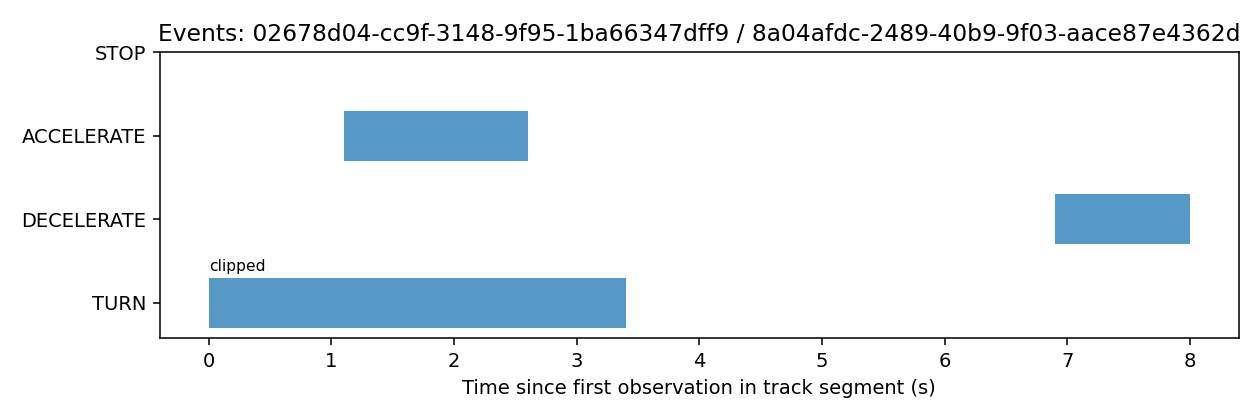

event_nodes.csv


,event_id,log_id,track_id,type,start,end,clipped
0,02678d04-cc9f-3148-9f95-1ba66347dff9:0e470e35-...,02678d04-cc9f-3148-9f95-1ba66347dff9,0e470e35-ac97-496e-adbb-1bf778dbdadf,ACCELERATE,6.200259,8.300412,False
1,02678d04-cc9f-3148-9f95-1ba66347dff9:393d935d-...,02678d04-cc9f-3148-9f95-1ba66347dff9,393d935d-9ef6-4f53-9af6-ad3ee23e7168,STOP,5.699935,11.000415,True
2,02678d04-cc9f-3148-9f95-1ba66347dff9:6247b383-...,02678d04-cc9f-3148-9f95-1ba66347dff9,6247b383-8d62-47cd-9da7-3dc66698b146,ACCELERATE,0.499655,2.700007,False
3,02678d04-cc9f-3148-9f95-1ba66347dff9:8a04afdc-...,02678d04-cc9f-3148-9f95-1ba66347dff9,8a04afdc-2489-40b9-9f03-aace87e4362d,DECELERATE,6.900307,8.000481,False
4,02678d04-cc9f-3148-9f95-1ba66347dff9:8a04afdc-...,02678d04-cc9f-3148-9f95-1ba66347dff9,8a04afdc-2489-40b9-9f03-aace87e4362d,ACCELERATE,1.100174,2.600470,False
5,02678d04-cc9f-3148-9f95-1ba66347dff9:8a04afdc-...,02678d04-cc9f-3148-9f95-1ba66347dff9,8a04afdc-2489-40b9-9f03-aace87e4362d,TURN,0.000000,3.400053,True
6,02678d04-cc9f-3148-9f95-1ba66347dff9:9054f80c-...,02678d04-cc9f-3148-9f95-1ba66347dff9,9054f80c-f0eb-4651-ac0a-b8a1e1e848ba,ACCELERATE,0.899782,3.800182,False
7,02678d04-cc9f-3148-9f95-1ba66347dff9:94dede14-...,02678d04-cc9f-3148-9f95-1ba66347dff9,94dede14-59da-4f09-b016-95f19596ac08,STOP,4.599763,15.700379,True
8,02678d04-cc9f-3148-9f95-1ba66347dff9:d5739055-...,02678d04-cc9f-3148-9f95-1ba66347dff9,d5739055-42d4-463b-ae79-7bcefae88a1c,STOP,0.000000,1.800227,True
9,02678d04-cc9f-3148-9f95-1ba66347dff9:d73dc255-...,02678d04-cc9f-3148-9f95-1ba66347dff9,d73dc255-ba6d-434c-bff2-cbbde6370656,TURN,0.400125,4.800159,False


relation_edges.csv


,source_event_id,relation,target_event_id
0,02678d04-cc9f-3148-9f95-1ba66347dff9:8a04afdc-...,THEN,02678d04-cc9f-3148-9f95-1ba66347dff9:8a04afdc-...
1,02678d04-cc9f-3148-9f95-1ba66347dff9:f291125f-...,WHILE,02678d04-cc9f-3148-9f95-1ba66347dff9:f291125f-...
2,02678d04-cc9f-3148-9f95-1ba66347dff9:f291125f-...,WHILE,02678d04-cc9f-3148-9f95-1ba66347dff9:f291125f-...


In [11]:
from IPython.display import display, Image
import pandas as pd
from collections import Counter
report = json.loads((OUT / "pilot_report.json").read_text(encoding="utf-8"))
print("데이터 출처:", report['acquisition']['source'])
print("데이터 종류:", report['data_source'])
print("로그 수:", report['acquisition']['log_count'])
print("평가 가능 차량 트랙 수:", report['track_count'])
print("행동 사건 수:", report['event_count'])
print("시간 관계 엣지 수:", report['graph']['typed_relation_edges'])
print("모든 TQP 동등성:", report['all_query_results_equal'])
print('전체 그래프 구축시간(ms):', report['graph_build_ms'])
print('Interval 질의 평균(ms):', report['mean_interval_query_ms'])
print('Graph 질의 평균(ms):', report['mean_graph_query_ms'])
print('원본 annotation ↔ pose 매칭 진단:')
display(pd.DataFrame(report['av2_log_diagnostics']))
display(pd.DataFrame(report['per_query'])[['query','equal','track_status_count']])
if (OUT/'events_preview.png').exists():
    display(Image(filename=str(OUT/'events_preview.png')))
else:
    print('검출 사건이 없어서 사건 그림은 생략되었습니다.')

# 사건/엣지 CSV를 직접 열어볼 수 있음
for filename in ('event_nodes.csv','relation_edges.csv'):
    p = OUT / filename
    if p.exists():
        print(filename)
        try:
            display(pd.read_csv(p).head(10))
        except pd.errors.EmptyDataError:
            print('빈 테이블')

## 7. 결과 Drive 저장 및 다운로드

`pilot_report.json`, 이벤트 노드/관계 엣지 CSV, 그림을 Drive에 보관합니다. `source_verification` 필드와 각 AV2 로그 식별자를 기록합니다.

In [12]:
import shutil
from datetime import datetime
save_dir = None
if DRIVE_MOUNTED and AV2_RESULTS_TO_DRIVE:
    stamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    save_dir = Path(DRIVE_SEARCH_ROOT)/'AV2_TEG_Pilot_Results'/f'{DATA_SPLIT}_{stamp}'
    shutil.copytree(OUT, save_dir)
    print('Drive saved:', save_dir)
else:
    print('Drive not mounted or saving disabled. Outputs remain at', OUT)

archive = shutil.make_archive(str(OUT), 'zip', root_dir=OUT)
print('Results ZIP:', archive)
try:
    from google.colab import files
    # 자동 다운로드 팝업은 피합니다. 원하는 경우 아래 두 줄의 주석을 해제합니다.
    # files.download(archive)
except ImportError:
    pass

Drive saved: /content/drive/MyDrive/AV2_TEG_Pilot_Results/val_20261014_105720
Results ZIP: /content/av2_teg_results/av2_val_3logs.zip


## 8. 분석 해석 및 연구 윤리

- `all_query_results_equal=True`는 **두 실행기가 같은 의미 판정식을 구현했다는 소프트웨어 검증**이지 Graph의 검색 정확도가 더 높다는 결과는 아닙니다.
- `mean_graph_query_ms`는 인덱스 구축 이후 질의 시간이며, `graph_build_ms`와 저장 비용도 함께 해석해야 합니다.
- `events_preview.png`의 사건은 예비 검출기의 출력입니다. TURN은 진행방향 변화로 추정하고, STOP/DECELERATE의 임계값은 과제 초안의 조작적 정의입니다.
- 기본 `val`은 개발 및 검증에만 사용하고, 최종 평가 데이터는 분리하십시오.
- `CainanD/RefAV`의 시나리오 마이닝 ground truth를 sensor log annotation과 혼동하지 마십시오.
- 실제로 실행하여 측정한 수치만 보고하고, 사용한 AI 도구와 구현 지원 범위는 Appendix AI Usage에 공개하십시오.

이 노트북은 TQP의 Graph 검색기 파일럿입니다. **직접 Python(B2) 대 TQP(P) LLM 비교는 별도 단계**입니다.